### Feature Engineering

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

datos = pd.read_csv('../../data/silver/cleaned_houses_inmuebles.csv')
datos.info()


<class 'pandas.DataFrame'>
RangeIndex: 498 entries, 0 to 497
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Total_area_m2  498 non-null    int64  
 1   Built_area_m2  498 non-null    int64  
 2   Rooms          498 non-null    int64  
 3   Bathrooms      498 non-null    int64  
 4   HalfBathrooms  498 non-null    int64  
 5   Parkings       498 non-null    int64  
 6   Colonia        498 non-null    str    
 7   Price          498 non-null    int64  
 8   PropertyType   498 non-null    str    
 9   Latitude       498 non-null    float64
 10  Longitude      498 non-null    float64
dtypes: float64(2), int64(7), str(2)
memory usage: 42.9 KB


<Axes: xlabel='Price', ylabel='Count'>

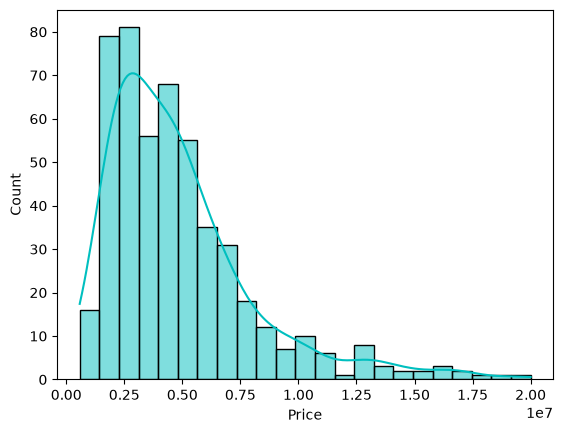

In [6]:
import seaborn as sns
sns.histplot(data=datos, x='Price', color='c', kde=True)

In [7]:
from sklearn.model_selection import train_test_split

x = datos.drop(columns=['Price'])
y = datos['Price']

x_train, x_test, y_train, y_test = train_test_split(x,y, train_size=0.8, random_state=777, shuffle=True)

In [8]:
from sklearn.preprocessing import PowerTransformer
pt_price = PowerTransformer(method='box-cox', standardize=True)
y_example =  pt_price.fit_transform(y_train.to_frame())


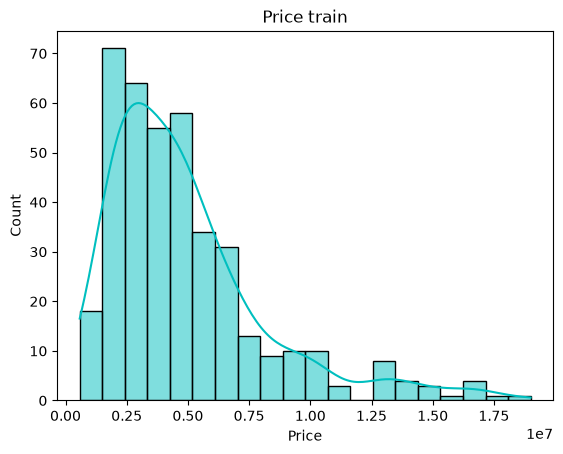

In [9]:
import seaborn as sns
sns.histplot(data=y_train, color='c', kde=True)
plt.title('Price train')
plt.show()


### total_area_m2

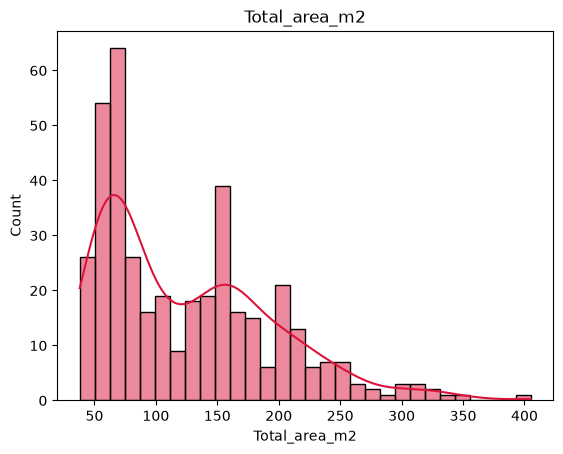

In [10]:
sns.histplot(data=x_train, x='Total_area_m2', color='crimson', kde=True, bins=30)
plt.title('Total_area_m2')
plt.show()

In [11]:
x_train['Total_area_m2'].describe()

count    398.000000
mean     125.582915
std       69.877020
min       38.000000
25%       65.000000
50%      105.000000
75%      169.500000
max      405.000000
Name: Total_area_m2, dtype: float64

### Built_area_m2

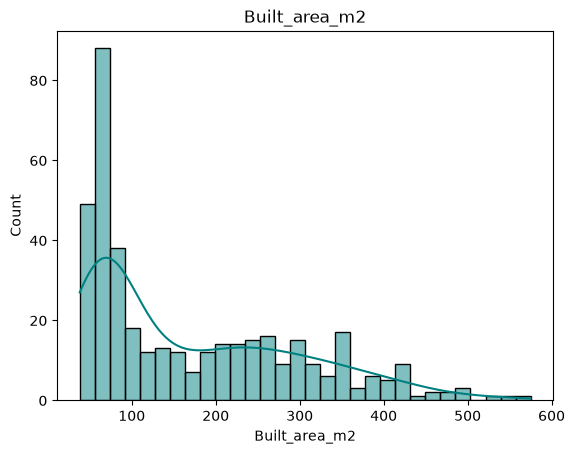

In [12]:
sns.histplot(data=x_train, x='Built_area_m2', color='teal', kde=True, bins=30)
plt.title('Built_area_m2')
plt.show()

In [13]:
x_train['Built_area_m2'].describe()

count    398.000000
mean     170.464824
std      123.826837
min       38.000000
25%       65.000000
50%      120.000000
75%      260.000000
max      575.000000
Name: Built_area_m2, dtype: float64

### Pipeline


In [14]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, PowerTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from category_encoders import TargetEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
import numpy as np

coordenadas = ['Latitude', 'Longitude']
areas = ['Total_area_m2', 'Built_area_m2']
categoricos_property = ['PropertyType']
categoricos_colonias = ['Colonia']

preprocessor = ColumnTransformer(
    transformers=[
        ('coordenadas',MinMaxScaler(),coordenadas),
        ('areas',PowerTransformer(method='box-cox', standardize=True),areas),
        ('categoricos_property',OneHotEncoder(handle_unknown='ignore'),categoricos_property),
        ('categoricos_colonias',TargetEncoder(smoothing=10.0), categoricos_colonias)
    ],
    remainder='passthrough'
)


### modelos

In [15]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from scipy.stats import uniform, randint

modelos = {
    'Ridge': Ridge(random_state=777),
    'Lasso': Lasso(random_state=777),
    'ElasticNet': ElasticNet(random_state=777),
    'RandomForest': RandomForestRegressor(random_state=777),
    'XGBoost': XGBRegressor(random_state=777, objective='reg:squarederror'),
    'CatBoost': CatBoostRegressor(random_state=777, verbose=False),
    'LightGBM': LGBMRegressor(random_state=777, verbose=-1)
}

parametros = {
    'Ridge': {'model__alpha': uniform(0.1, 10.0)},
    'Lasso': {'model__alpha': uniform(0.01, 1.0)},
    'ElasticNet': {'model__alpha': uniform(0.01, 1.0), 'model__l1_ratio': uniform(0.0, 1.0)},
    'RandomForest': {'model__n_estimators': randint(50, 200), 'model__max_depth': [None, 10, 20]},
    'XGBoost': {'model__n_estimators': randint(50, 200), 'model__learning_rate': uniform(0.01, 0.2), 'model__max_depth': randint(3, 8)},
    'CatBoost': {'model__iterations': randint(50, 200), 'model__learning_rate': uniform(0.01, 0.2), 'model__depth': randint(4, 8)},
    'LightGBM': {'model__n_estimators': randint(50, 200), 'model__learning_rate': uniform(0.01, 0.2), 'model__num_leaves': randint(20, 100)}
}

# 5. Entrenamiento y evaluación
mejores_modelos = {}
resultados = []
cv = KFold(n_splits=5, shuffle=True, random_state=777)


for nombre, modelo in modelos.items():
    print(f"Entrenando {nombre}...")
    
    # Crear Pipeline: preprocesamiento de X y regresor sobre el precio original
    pipeline = Pipeline([
        ('preprocesador', preprocessor),
        ('model', modelo)
    ])
    
    # Random Search CV
    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parametros[nombre],
        n_iter=50, # Ajusta este valor según tu capacidad de cómputo (10 a 50 es ideal)
        cv=cv,
        scoring='neg_mean_squared_error',
        n_jobs=-1,
        random_state=777
    )
    
    # Entrenar
    random_search.fit(x_train, y_train)
    mejor_modelo = random_search.best_estimator_
    mejores_modelos[nombre] = mejor_modelo
    
    # Predicciones
    y_pred = mejor_modelo.predict(x_test)
    
    # Métricas
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    # R2 Ajustado
    n = len(y_test)
    p = x_test.shape[1]
    r2_adj = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
    
    resultados.append({
        'Modelo': nombre,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE': mape,
        'R2': r2,
        'R2 Ajustado': r2_adj,
        'Mejores Params': str(random_search.best_params_)
    })

# 6. Mostrar tabla de rendimiento
df_resultados = pd.DataFrame(resultados)
# Ordenamos por RMSE (el valor más bajo es mejor)
df_resultados = df_resultados.sort_values(by='RMSE', ascending=True).reset_index(drop=True)

print("\n--- Rendimiento de los Modelos ---")
# Mostrar en consola de forma tabulada (requiere librería 'tabulate', o se imprime directo)
print(df_resultados[['Modelo', 'MAE', 'RMSE', 'MAPE', 'R2', 'R2 Ajustado']].to_string(index=False))

# 7. Seleccionar el mejor
mejor_nombre = df_resultados.iloc[0]['Modelo']
mejor_r2 = df_resultados.iloc[0]['R2']
print(f"\nEl mejor modelo es: {mejor_nombre} con un R2 de {mejor_r2:.4f}")

Entrenando Ridge...
Entrenando Lasso...
Entrenando ElasticNet...


d:\Proyectos_personales\Zacah_Valuer\venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.697544e+14, tolerance: 4.242e+11
  model = cd_fast.enet_coordinate_descent(


Entrenando RandomForest...
Entrenando XGBoost...
Entrenando CatBoost...
Entrenando LightGBM...

--- Rendimiento de los Modelos ---
      Modelo          MAE         RMSE     MAPE       R2  R2 Ajustado
    CatBoost 7.406527e+05 1.202702e+06 0.152049 0.822577     0.802642
     XGBoost 8.129965e+05 1.205219e+06 0.177994 0.821833     0.801815
RandomForest 7.892124e+05 1.222977e+06 0.174906 0.816544     0.795931
    LightGBM 9.262756e+05 1.414550e+06 0.200222 0.754568     0.726992
       Lasso 1.055783e+06 1.551678e+06 0.244601 0.704677     0.671494
       Ridge 1.058323e+06 1.552806e+06 0.244835 0.704247     0.671017
  ElasticNet 1.062779e+06 1.555151e+06 0.245185 0.703353     0.670022

El mejor modelo es: CatBoost con un R2 de 0.8226


In [24]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_validate

# Seleccionar el mejor modelo
mejor_nombre = df_resultados.iloc[0]['Modelo']
mejor_modelo = mejores_modelos[mejor_nombre]

print(f"Modelo seleccionado: {mejor_nombre}")

# Validación cruzada
cv = KFold(n_splits=5, shuffle=True, random_state=777)

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'MSE': 'neg_mean_squared_error',
    'R2': 'r2'
}

resultados_cv = cross_validate(
    estimator=mejor_modelo,
    X=x_train,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

# Construir tabla de métricas por fold
df_folds = pd.DataFrame({
    'Fold': np.arange(1, 6),

    'MAE_Train': -resultados_cv['train_MAE'],
    'MAE_Validacion': -resultados_cv['test_MAE'],

    'RMSE_Train': np.sqrt(-resultados_cv['train_MSE']),
    'RMSE_Validacion': np.sqrt(-resultados_cv['test_MSE']),

    'R2_Train': resultados_cv['train_R2'],
    'R2_Validacion': resultados_cv['test_R2']
})

# Brechas entre entrenamiento y validación
df_folds['Brecha_RMSE'] = (
    df_folds['RMSE_Validacion'] - df_folds['RMSE_Train']
)

df_folds['Brecha_R2'] = (
    df_folds['R2_Train'] - df_folds['R2_Validacion']
)

print("\nMétricas por fold:")
print(df_folds.round(4).to_string(index=False))

Modelo seleccionado: CatBoost

Métricas por fold:
 Fold   MAE_Train  MAE_Validacion  RMSE_Train  RMSE_Validacion  R2_Train  R2_Validacion  Brecha_RMSE  Brecha_R2
    1 375724.8929    1099737.6812 505896.1322     1535542.8142    0.9757         0.7889 1029646.6821     0.1868
    2 330397.8529    1081409.0951 453693.4737     1709100.3643    0.9800         0.7587 1255406.8906     0.2213
    3 332414.3885    1101071.7777 451787.4710     1734555.2823    0.9820         0.6173 1282767.8112     0.3647
    4 354570.3316     960660.3901 478580.7452     1475582.0648    0.9776         0.8151  997001.3196     0.1625
    5 347563.5171     989356.5749 465798.6482     1598463.5541    0.9800         0.7325 1132664.9059     0.2476


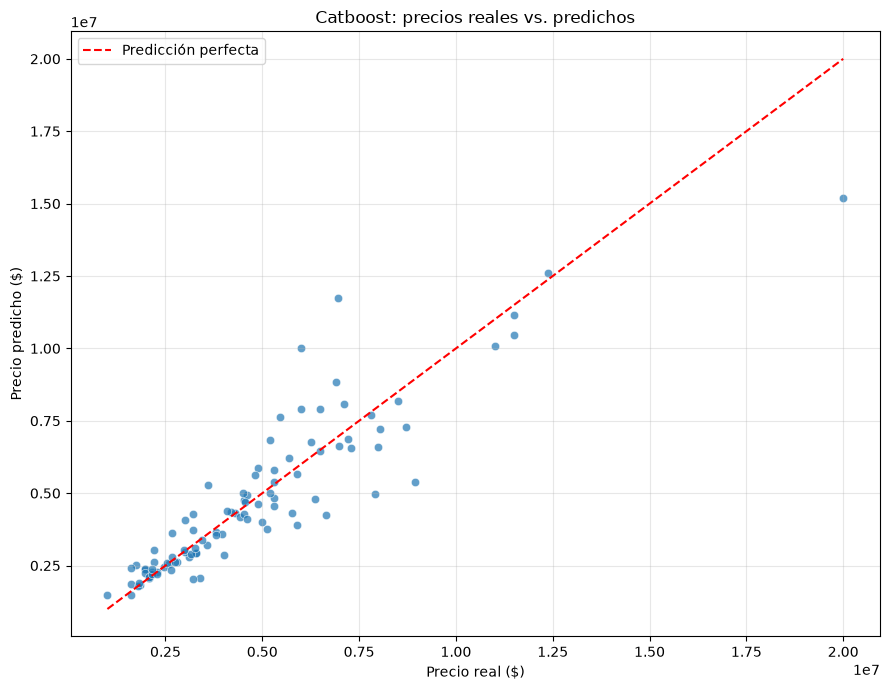

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

modelo_catBoost = mejores_modelos['CatBoost']

y_pred = modelo_catBoost.predict(x_test)

resultados_casas = x_test.copy()

resultados_casas['Precio_real'] = np.asarray(y_test)
resultados_casas['Precio_predicho'] = y_pred

resultados_casas['Error'] = (
    resultados_casas['Precio_real'] -
    resultados_casas['Precio_predicho']
)

resultados_casas['Error_absoluto'] = resultados_casas['Error'].abs()

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=resultados_casas,
    x='Precio_real',
    y='Precio_predicho',
    alpha=0.7
)

limite_min = min(
    resultados_casas['Precio_real'].min(),
    resultados_casas['Precio_predicho'].min()
)

limite_max = max(
    resultados_casas['Precio_real'].max(),
    resultados_casas['Precio_predicho'].max()
)

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle='--',
    color='red',
    label='Predicción perfecta'
)

plt.xlabel('Precio real ($)')
plt.ylabel('Precio predicho ($)')
plt.title('Catboost: precios reales vs. predichos')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [28]:
# Unir información original con resultados
resultados_casas = datos.loc[x_test.index].copy()

resultados_casas['Precio_real'] = np.asarray(y_test)
resultados_casas['Precio_predicho'] = y_pred

resultados_casas['Error'] = (
    resultados_casas['Precio_real'] -
    resultados_casas['Precio_predicho']
)

resultados_casas['Error_absoluto'] = resultados_casas['Error'].abs()

# Seleccionar las 20 viviendas con mayores errores
peores_casas = resultados_casas.nlargest(20, 'Error_absoluto')

# Visualización
plt.figure(figsize=(12, 7))

sns.barplot(
    data=peores_casas,
    x='Error_absoluto',
    y=peores_casas.index.astype(str),
    color='steelblue'
)

plt.xlabel('Error absoluto ($)')
plt.ylabel('Índice de la vivienda')
plt.title('Las 20 viviendas con mayores errores de predicción')
plt.tight_layout()
plt.show()

AttributeError: 'dict' object has no attribute 'loc'

<hr />

### Cambio de perspectiva

In [18]:
import pandas as pd

clasificacion_colonias = {
    # Nivel 1: menor atractivo residencial
    "1": [
        "granjas_modernas",
        "pradera_ii_secc",
        "el_coyol",
        "barrio_candelaria_ticoman",
        "guadalupe_proletaria",
        "ampliacion_providencia",
        "nueva_atzacoalco",
        "dm_nacional",
        "martires_de_rio_blanco",
        "constitucion_de_la_republica",
        "la_malinche",
        "santiago_atzacoalco",
        "san_pedro_el_chico",
        "tablas_de_san_agustin",
        "san_felipe_de_jesus",
        "salvador_diaz_miron",
        "nueva_vallejo",
        "la_pradera",
        "juventino_rosas",
        "25_de_julio",
        "jorge_negrete",
        "ampliacion_gabriel_hernandez",
        "bondojito",
        "la_joyita",
        "ex_escuela_de_tiro",
        "zona_escolar",
        "la_joya",
        "emiliano_zapata",
        "ampliacion_casas_aleman",
        "progreso_nacional",
        "gertrudis_sanchez",
        "tres_estrellas",
        "zona_escolar_oriente",
        "ampliacion_martires_de_rio_blanco",
        "el_arbolillo",
        "cuchilla_del_tesoro",
        "nueva_tenochtitlan",
        "cuautepec_de_madero",
        "campestre_aragon",
        "fernando_casas_aleman",
        "loma_la_palma",
        "del_obrero",
        "prados_de_cuautepec",
        "juan_gonzalez_romero",
        "general_felipe_berriozabal",
        "c.t.m._aragon",
        "maximino_avila_camacho",
        "c.t.m._el_risco",
    ],

    # Nivel 2: atractivo residencial intermedio
    "2": [
        "panamericana",
        "ferrocarrilera",
        "industrial",
        "villa_gustavo_a._madero",
        "15_de_agosto",
        "san_juan_de_aragon",
        "gustavo_a._madero",
        "magdalena_de_las_salinas",
        "vallejo",
        "guadalupe_insurgentes",
        "acueducto_de_guadalupe",
        "villa_de_aragon",
        "providencia",
        "san_jose_de_la_escalera",
        "santa_isabel_tola",
        "vasco_de_quiroga",
        "faja_de_oro",
        "estrella",
        "la_purisima_ticoman",
        "san_bartolo_atepehuacan",
        "aragon_la_villa",
        "lindavista_vallejo",
        "lindavista_vallejo_ii_secc",
        "san_juan_de_aragon_iii_secc",
        "san_juan_de_aragon_v_secc",
        "7_de_noviembre",
        "san_juan_de_aragon_i_secc",
        "san_juan_de_aragon_vi_secc",
        "ticoman",
        "defensores_de_la_republica",
        "san_juan_de_aragon_ii_secc",
        "la_escalera",
        "residencial_acueducto_de_guadalupe",
        "juan_de_dios_batiz",
        "ampliacion_san_juan_de_aragon",
        "la_patera_vallejo",
        "san_juan_de_aragon_iv_secc",
        "chalma_de_guadalupe",
        "gabriel_hernandez",
    ],

    # Nivel 3: mayor atractivo residencial
    "3": [
        "guadalupe_tepeyac",
        "lindavista_norte",
        "lindavista",
        "lindavista_sur",
        "santa_maria_ticoman",
        "planetario_lindavista",
        "nueva_industrial_vallejo",
        "valle_del_tepeyac",
        "torres_lindavista",
        "residencial_zacatenco",
        "tepeyac_insurgentes",
    ],
}

# Convertir las listas en una sola Serie
datos = {
    colonia: int(nivel)
    for nivel, colonias in clasificacion_colonias.items()
    for colonia in colonias
}

serie_colonias = pd.Series(datos, name="clasificacion")

# Mostrar las colonias ordenadas de menor a mayor clasificación
serie_colonias = serie_colonias.sort_values()

print(serie_colonias)

granjas_modernas             1
pradera_ii_secc              1
el_coyol                     1
barrio_candelaria_ticoman    1
guadalupe_proletaria         1
                            ..
nueva_industrial_vallejo     3
valle_del_tepeyac            3
torres_lindavista            3
residencial_zacatenco        3
tepeyac_insurgentes          3
Name: clasificacion, Length: 98, dtype: int64


In [19]:
datos_2 = pd.read_csv('../../data/silver/cleaned_houses_inmuebles.csv')
datos_2['Colonia_Score'] = datos_2['Colonia'].map(serie_colonias)

# Identificar colonias sin clasificación
print(datos_2.loc[datos_2['Colonia_Score'].isna(), 'Colonia'].unique())

<StringArray>
[]
Length: 0, dtype: str


In [20]:
print("Viviendas sin clasificación:", datos_2['Colonia_Score'].isna().sum())
print("Porcentaje sin clasificación:", datos_2['Colonia_Score'].isna().mean() * 100, "%")

Viviendas sin clasificación: 0
Porcentaje sin clasificación: 0.0 %


In [21]:
x = datos_2.drop(columns=['Price'])
y = datos_2['Price']

x_train_2, x_test_2, y_train_2, y_test_2 = train_test_split(x,y, train_size=0.8, random_state=777, shuffle=True)

In [22]:
coordenadas = ['Latitude', 'Longitude']

areas = ['Total_area_m2', 'Built_area_m2']

categoricos_property = ['PropertyType']

categoricos_colonias = ['Colonia']

score_colonia = ['Colonia_Score']

preprocessor = ColumnTransformer(
    transformers=[
        ('coordenadas', MinMaxScaler(), coordenadas),
        ('areas', PowerTransformer(method='box-cox', standardize=True), areas),
        ('categoricos_property', OneHotEncoder(handle_unknown='ignore'), categoricos_property),
        ('categoricos_colonias', TargetEncoder(smoothing=10.0), categoricos_colonias),
        ('score_colonia', MinMaxScaler(), score_colonia)
    ],
    remainder='passthrough'
)

In [23]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from scipy.stats import uniform, randint

modelos = {
    'Ridge': Ridge(random_state=777),
    'Lasso': Lasso(random_state=777),
    'ElasticNet': ElasticNet(random_state=777),
    'RandomForest': RandomForestRegressor(random_state=777),
    'XGBoost': XGBRegressor(random_state=777, objective='reg:squarederror'),
    'CatBoost': CatBoostRegressor(random_state=777, verbose=False),
    'LightGBM': LGBMRegressor(random_state=777, verbose=-1)
}

parametros = {
    'Ridge': {'model__regressor__alpha': uniform(0.1, 10.0)},
    'Lasso': {'model__regressor__alpha': uniform(0.01, 1.0)},
    'ElasticNet': {'model__regressor__alpha': uniform(0.01, 1.0), 'model__regressor__l1_ratio': uniform(0.0, 1.0)},
    'RandomForest': {'model__regressor__n_estimators': randint(50, 200), 'model__regressor__max_depth': [None, 10, 20]},
    'XGBoost': {'model__regressor__n_estimators': randint(50, 200), 'model__regressor__learning_rate': uniform(0.01, 0.2), 'model__regressor__max_depth': randint(3, 8)},
    'CatBoost': {'model__regressor__iterations': randint(50, 200), 'model__regressor__learning_rate': uniform(0.01, 0.2), 'model__regressor__depth': randint(4, 8)},
    'LightGBM': {'model__regressor__n_estimators': randint(50, 200), 'model__regressor__learning_rate': uniform(0.01, 0.2), 'model__regressor__num_leaves': randint(20, 100)}
}

# 5. Entrenamiento y evaluación
resultados = []
cv = KFold(n_splits=5, shuffle=True, random_state=777)
mejores_modelos_2 = {}

for nombre, modelo in modelos.items():
    print(f"Entrenando {nombre}...")
    
    # Envolver el modelo para que 'y' aplique Box-Cox internamente
    modelo_objetivo = TransformedTargetRegressor(
        regressor=modelo,
        transformer=PowerTransformer(method='box-cox', standardize=True)
    )
    
    # Crear Pipeline: Preprocesamiento de X + Modelo con Y transformada
    pipeline = Pipeline([
        ('preprocesador', preprocessor),
        ('model', modelo_objetivo)
    ])
    
    # Random Search CV
    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parametros[nombre],
        n_iter=50, # Ajusta este valor según tu capacidad de cómputo (10 a 50 es ideal)
        cv=cv,
        scoring='neg_mean_squared_error',
        n_jobs=-1,
        random_state=777
    )
    
    # Entrenar
    random_search.fit(x_train_2, y_train_2)
    mejor_modelo_2 = random_search.best_estimator_
    mejores_modelos_2[nombre] = mejor_modelo_2
    
    # Predicciones
    y_pred_2 = mejor_modelo_2.predict(x_test_2)
    
    # Métricas
    mae = mean_absolute_error(y_test_2, y_pred_2)
    mse = mean_squared_error(y_test_2, y_pred_2)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_test_2, y_pred_2)
    r2 = r2_score(y_test_2, y_pred_2)
    
    # R2 Ajustado
    n = len(y_test_2)
    p = x_test_2.shape[1]
    r2_adj = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
    
    resultados.append({
        'Modelo': nombre,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'MAPE': mape,
        'R2': r2,
        'R2 Ajustado': r2_adj,
        'Mejores Params': str(random_search.best_params_)
    })

# 6. Mostrar tabla de rendimiento
df_resultados = pd.DataFrame(resultados)
# Ordenamos por RMSE (el valor más bajo es mejor)
df_resultados = df_resultados.sort_values(by='RMSE', ascending=True).reset_index(drop=True)

print("\n--- Rendimiento de los Modelos ---")
# Mostrar en consola de forma tabulada (requiere librería 'tabulate', o se imprime directo)
print(df_resultados[['Modelo', 'MAE', 'RMSE', 'MAPE', 'R2', 'R2 Ajustado']].to_string(index=False))

# 7. Seleccionar el mejor
mejor_nombre_2 = df_resultados.iloc[0]['Modelo']
mejor_r2_2 = df_resultados.iloc[0]['R2']
print(f"\nEl mejor modelo es: {mejor_nombre_2} con un R2 de {mejor_r2_2:.4f}")

Entrenando Ridge...


NameError: name 'TransformedTargetRegressor' is not defined

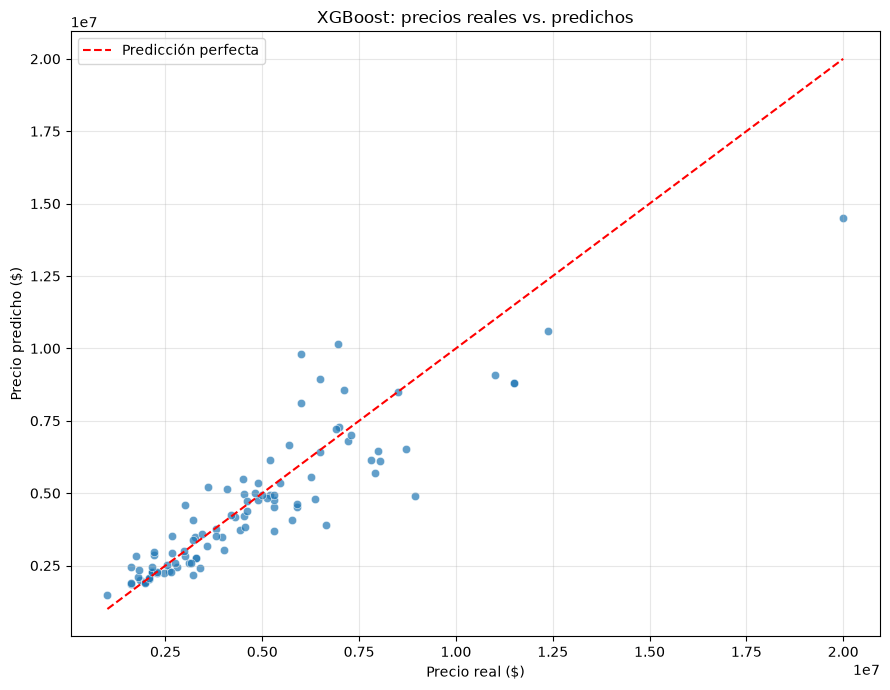

In [ ]:
modelo_xgb = mejores_modelos_2['CatBoost']

y_pred = modelo_xgb.predict(x_test_2)

resultados_casas = x_test_2.copy()

resultados_casas['Precio_real'] = np.asarray(y_test_2)
resultados_casas['Precio_predicho'] = y_pred

resultados_casas['Error'] = (
    resultados_casas['Precio_real'] -
    resultados_casas['Precio_predicho']
)

resultados_casas['Error_absoluto'] = resultados_casas['Error'].abs()

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=resultados_casas,
    x='Precio_real',
    y='Precio_predicho',
    alpha=0.7
)

limite_min = min(
    resultados_casas['Precio_real'].min(),
    resultados_casas['Precio_predicho'].min()
)

limite_max = max(
    resultados_casas['Precio_real'].max(),
    resultados_casas['Precio_predicho'].max()
)

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle='--',
    color='red',
    label='Predicción perfecta'
)

plt.xlabel('Precio real ($)')
plt.ylabel('Precio predicho ($)')
plt.title('XGBoost: precios reales vs. predichos')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

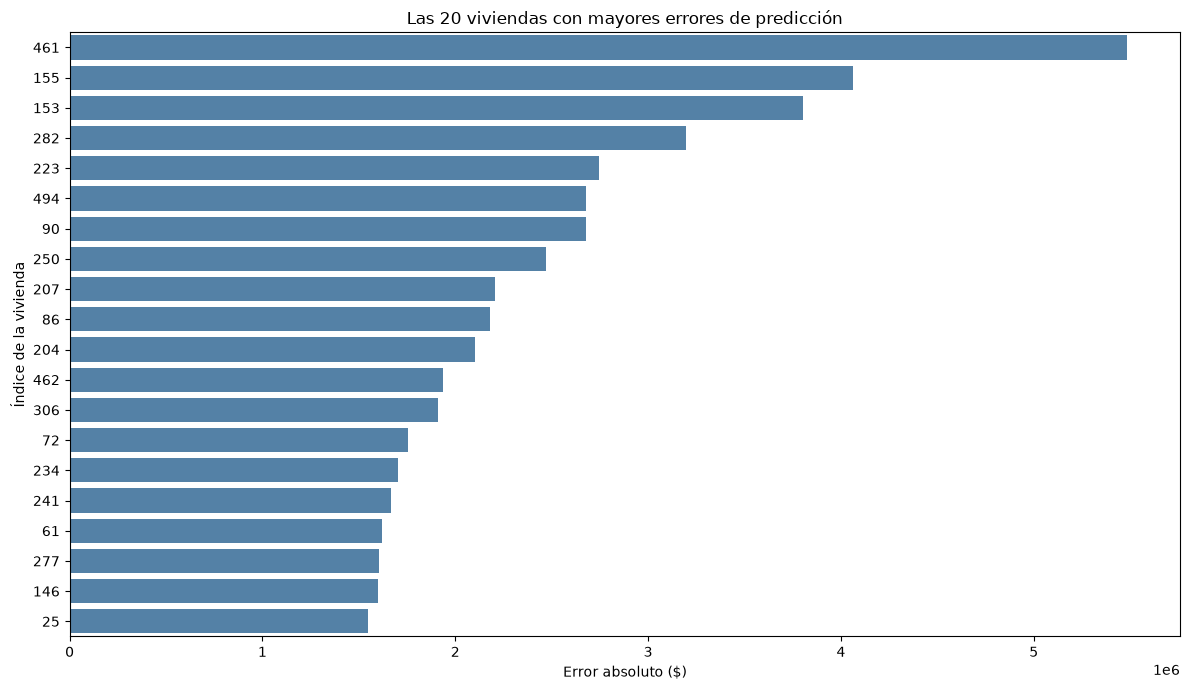

In [ ]:
# Unir información original con resultados
resultados_casas = datos_2.loc[x_test_2.index].copy()

resultados_casas['Precio_real'] = np.asarray(y_test_2)
resultados_casas['Precio_predicho'] = y_pred

resultados_casas['Error'] = (
    resultados_casas['Precio_real'] -
    resultados_casas['Precio_predicho']
)

resultados_casas['Error_absoluto'] = resultados_casas['Error'].abs()

# Seleccionar las 20 viviendas con mayores errores
peores_casas = resultados_casas.nlargest(20, 'Error_absoluto')

# Visualización
plt.figure(figsize=(12, 7))

sns.barplot(
    data=peores_casas,
    x='Error_absoluto',
    y=peores_casas.index.astype(str),
    color='steelblue'
)

plt.xlabel('Error absoluto ($)')
plt.ylabel('Índice de la vivienda')
plt.title('Las 20 viviendas con mayores errores de predicción')
plt.tight_layout()
plt.show()

In [ ]:
columnas = [
    'Colonia',
    'PropertyType',
    'Total_area_m2',
    'Built_area_m2',
    'Rooms',
    'Bathrooms',
    'Parkings',
    'Precio_real',
    'Precio_predicho',
    'Error',
    'Error_absoluto'
]

print(
    peores_casas[columnas]
    .sort_values('Error_absoluto', ascending=False)
    .to_string()
)

                        Colonia PropertyType  Total_area_m2  Built_area_m2  Rooms  Bathrooms  Parkings  Precio_real  Precio_predicho         Error  Error_absoluto
461                  lindavista         Casa            275            425      3          3         4     20000000     1.451581e+07  5.484190e+06    5.484190e+06
155            nueva_atzacoalco         Casa            161            343      3          4         3      8950000     4.886258e+06  4.063742e+06    4.063742e+06
153         tepeyac_insurgentes         Casa            231            200      4          3         3      5995000     9.799222e+06 -3.804222e+06    3.804222e+06
282                  lindavista         Casa            260            260      4          4         2      6950000     1.014743e+07 -3.197435e+06    3.197435e+06
223     ampliacion_casas_aleman         Casa            140            217      4          2         3      6645000     3.899384e+06  2.745616e+06    2.745616e+06
494           torres_l

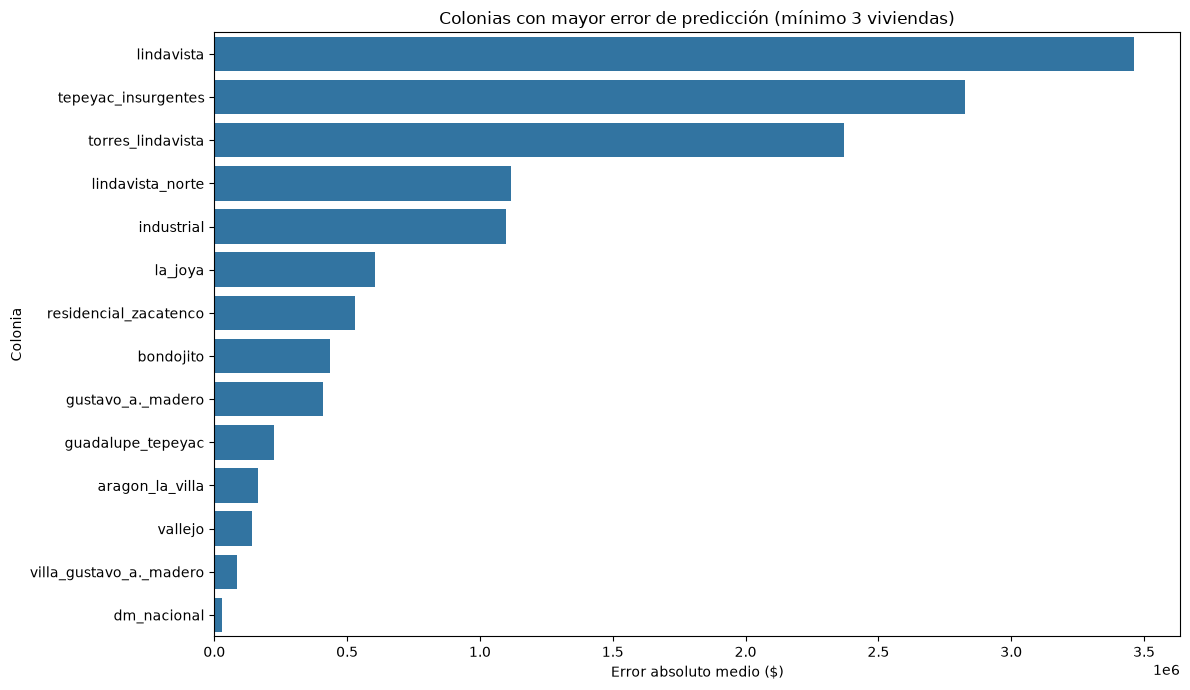

In [ ]:
errores_colonia = (
    resultados_casas
    .groupby('Colonia')
    .agg(
        MAE=('Error_absoluto', 'mean'),
        Viviendas=('Error_absoluto', 'size')
    )
    .query('Viviendas >= 3')
    .sort_values('MAE', ascending=False)
    .head(15)
    .reset_index()
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=errores_colonia,
    x='MAE',
    y='Colonia'
)

plt.xlabel('Error absoluto medio ($)')
plt.ylabel('Colonia')
plt.title('Colonias con mayor error de predicción (mínimo 3 viviendas)')
plt.tight_layout()
plt.show()